In [1]:
import matplotlib.pyplot as plt
from granad import *

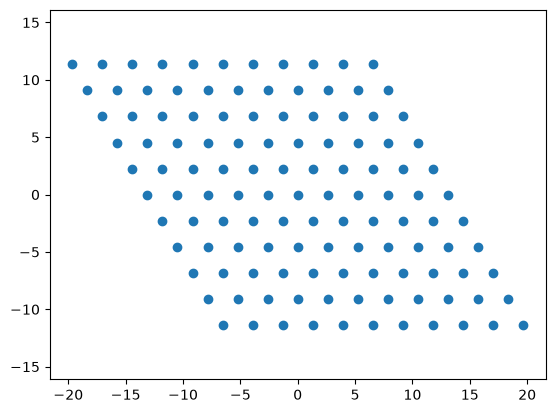

In [2]:
lattice_constant = 2.62 # Å
lattice_basis = [[1, 0, 0], [-0.5, jnp.sqrt(3)/2, 0]] 

# au_s_hoppings = [-0.21077006 + 1.1, -0.5814]   # PARAMETERS TUNED MANUALLY TO FIT THE EXPECTED ENERGY BAND :)

au_s_hoppings = [-0.21077006, -0.1314]   # PARAMETERS TUNED MANUALLY TO FIT THE EXPECTED ENERGY BAND :)


goldene = (Material("Au")
        .lattice_constant(lattice_constant)  # Approximate lattice constant of hBN
        .lattice_basis(lattice_basis)
        .add_orbital_species("s_gold", atom='Au')
        .add_orbital(position=(0, 0), tag="Au_s", species="s_gold")
        .add_interaction(
            "hamiltonian",
            participants=("s_gold", "s_gold"),
            parameters=au_s_hoppings,  
        )   )

flake = goldene.cut_flake(Rectangle(0.5, 0.5), minimum_neighbor_number = 0)

lattice_vectors = lattice_constant*jnp.array([
    [1, 0, 0],
    [-0.5, jnp.sqrt(3)/2, 0] ])
fourier_cutoff = 4

bulk = Periodic(flake, lattice_vectors, fourier_cutoff)
bulk.show_2d(5)

In [3]:
ks = bulk.get_kgrid_monkhorst_pack([99, 99])
vals, vecs = bulk.get_eigenbasis(ks)

mu = bulk.get_mu(vals)
print(f"Mu is {mu}")

fermi_energy = bulk.get_fermi_energy(vals, sigma=0.01)
print(f"Fermi energy with Gaussian smearing (sigma = 0.01) = {fermi_energy}")

fermi_energy = bulk.get_fermi_energy(vals, sigma=0.1)
print(f"Fermi energy with Gaussian smearing (sigma = 0.1) = {fermi_energy}")

fermi_energy = bulk.get_fermi_energy(vals, sigma=0.2)
print(f"Fermi energy with Gaussian smearing (sigma = 0.2) = {fermi_energy}")

Mu is -0.10019694866196396
Fermi energy with Gaussian smearing (sigma = 0.01) = -0.10017006000001016
Fermi energy with Gaussian smearing (sigma = 0.1) = -0.11817006000010921
Fermi energy with Gaussian smearing (sigma = 0.2) = -0.15017006000021937
